Period T = 86.910354 days
Start state at I peak: S=0.285714, I=0.031124, v=0.944508
Dose = 0.1, horizon = 365 days (4.20 cycles)


largest next-peak reduction : tau =  80.98 d (1.864 pi)   +4.360%
largest cumulative reduction: tau =  80.98 d (1.864 pi)   +0.388%
best averted per dose       : tau =  80.98 d (1.864 pi)   +0.1655
S maximum                   : tau =  76.05 d (1.750 pi)   S = 0.4394
Z_v maximum                 : tau =  81.32 d (1.871 pi)
Z_v minimum                 : tau =  11.49 d (0.265 pi)

worst-to-best spread, cumulative reduction: +0.007% to +0.388%
dose was capped below 0.1 at 11 of 88 phases


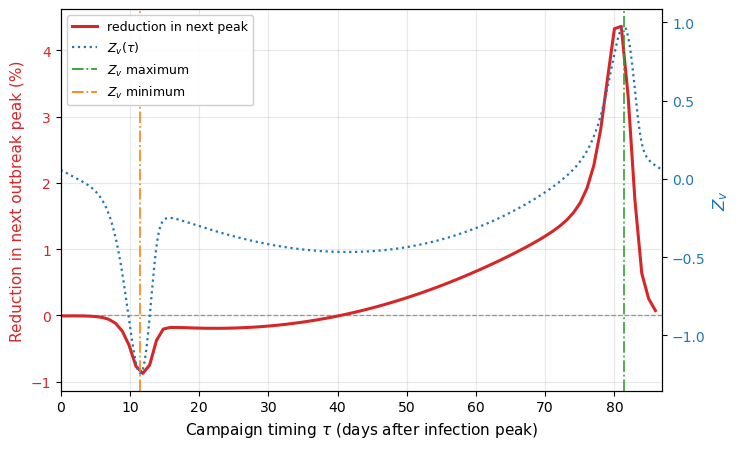

In [15]:
"""
Figure: reduction in the next outbreak peak as a function of campaign timing.

Pure simulation, no phase reduction.  The system is settled onto its limit
cycle, a SINGLE campaign v -> min(v + DOSE, 1) is applied tau days after an
infection peak, and the result is compared against the identical trajectory
without the campaign.  tau is swept over one full period.

Reported per tau:
    next-outbreak peak I      (first I maximum after the campaign)
    cumulative I              (integral of I over HORIZON days from the campaign)
    infections averted        (baseline minus campaign, both quantities)
    averted per unit dose     (cumulative averted / dose actually delivered)

The baseline trajectory does not depend on tau, so it is computed once and
re-evaluated on each tau's window via dense output.
"""

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

_trapz = getattr(np, 'trapezoid', None) or np.trapz   # numpy 1.x / 2.x


# =============================================================================
# SETTINGS
# =============================================================================

params = {
    'alpha': 0.01,
    'beta': 0.5,
    'gamma': 1/7,
    'eta': 1/7,
    'theta': 0.01,
    'kappa': 300,
    'rho': 0.01,
}

y0_init = [0.49, 0.01, 0.01]

DOSE = 0.10            # additive bump to v, capped at 1
HORIZON = 365.0        # days of follow-up from the campaign
N_TAU = 88             # tau grid points over [0, T)  (~1 day spacing)
DT_OUT = 0.01          # output resolution for peaks and integrals
RTOL = ATOL = 1e-10

OUTFILE = 'campaign_timing.png'


# =============================================================================
# SYSTEM
# =============================================================================

def f(t, y, p):
    """Uncoupled smooth SIRv system. y = [S, I, v]"""
    S, I, v = y
    dS = p['alpha']*(1 - S - I) - p['beta']*S*I - p['eta']*v*S
    dI = -p['gamma']*I + p['beta']*S*I
    dv = -v + 1/(1 + np.exp(-p['kappa']*(p['beta']*I - p['rho']
                                         - p['theta']*(1 - 2*v))))
    return [dS, dI, dv]


def rhs(t, y):
    return f(t, y, params)


def ev_Imax(t, y):
    """dI/dt = I*(beta*S - gamma); zero with direction -1 is an I maximum."""
    return y[1]*(params['beta']*y[0] - params['gamma'])


ev_Imax.direction = -1.0


# =============================================================================
# STEP 1: SETTLE ONTO THE LIMIT CYCLE, START AT AN INFECTION PEAK
# =============================================================================

settle = solve_ivp(rhs, (0, 5000), y0_init, method='LSODA',
                   rtol=RTOL, atol=ATOL)

pk = solve_ivp(rhs, (0, 1000), settle.y[:, -1], method='LSODA',
               rtol=RTOL, atol=ATOL, events=ev_Imax)

peak_times = pk.t_events[0]
T = float(np.mean(np.diff(peak_times[-5:])))
y0 = pk.y_events[0][-3].copy()          # a peak with room to run afterwards

print(f"Period T = {T:.6f} days")
print(f"Start state at I peak: S={y0[0]:.6f}, I={y0[1]:.6f}, v={y0[2]:.6f}")
print(f"Dose = {DOSE}, horizon = {HORIZON:.0f} days "
      f"({HORIZON/T:.2f} cycles)\n")


# =============================================================================
# STEP 1b: iPRC LANDMARKS FOR THE FIGURE
# =============================================================================

n_points = 20000
n_periods = 20

t_cycle = np.linspace(0, T, n_points)

sol_cycle = solve_ivp(
    lambda t, y: f(t, y, params),
    [0, T],
    y0,
    method='LSODA',
    t_eval=t_cycle,
    rtol=RTOL,
    atol=ATOL
)


class Gamma:
    t = sol_cycle.t
    S = sol_cycle.y[0, :]
    I = sol_cycle.y[1, :]
    v = sol_cycle.y[2, :]
    T = T
    y = sol_cycle.y


S_sym, I_sym, v_sym = sp.symbols('S I v')
alpha_sym, beta_sym, gamma_sym, eta_sym = sp.symbols('alpha beta gamma eta')
theta_sym, kappa_sym, rho_sym = sp.symbols('theta kappa rho')

F1 = alpha_sym*(1 - S_sym - I_sym) - beta_sym*S_sym*I_sym - eta_sym*v_sym*S_sym
F2 = -gamma_sym*I_sym + beta_sym*S_sym*I_sym
F3 = -v_sym + 1/(1 + sp.exp(-kappa_sym*(beta_sym*I_sym - rho_sym
                                        - theta_sym*(1 - 2*v_sym))))

F = sp.Matrix([F1, F2, F3])
state = sp.Matrix([S_sym, I_sym, v_sym])

DF_symbolic = F.jacobian(state)

param_symbols = (alpha_sym, beta_sym, gamma_sym, eta_sym,
                 theta_sym, kappa_sym, rho_sym)
all_symbols = (S_sym, I_sym, v_sym) + param_symbols

DF_func = sp.lambdify(all_symbols, DF_symbolic, modules='numpy')


def compute_DF(S, I, v, params):
    return np.array(DF_func(
        S, I, v,
        params['alpha'], params['beta'], params['gamma'], params['eta'],
        params['theta'], params['kappa'], params['rho']
    ))


A = np.zeros((n_points, 3, 3))
for i in range(n_points):
    A[i] = compute_DF(Gamma.S[i], Gamma.I[i], Gamma.v[i], params)

Gamma_dot = np.zeros((3, n_points))
for i in range(n_points):
    Gamma_dot[:, i] = f(Gamma.t[i], Gamma.y[:, i], params)

Gamma.S_dot = Gamma_dot[0, :]
Gamma.I_dot = Gamma_dot[1, :]
Gamma.v_dot = Gamma_dot[2, :]
Gamma.y_dot = Gamma_dot

A_interp_base = interp1d(Gamma.t, A, axis=0, kind='linear',
                         fill_value='extrapolate')


def A_interp_periodic(t):
    t_mod = np.mod(t, Gamma.T)
    return A_interp_base(t_mod)


def adjoint_equation_reversed_periodic(s, Z, T):
    A_t = A_interp_periodic(T - (s % T))
    return A_t.T @ Z


total_time = n_periods * Gamma.T

Z_initial = np.array([1.0, 1.0, 1.0])

n_points_total = n_points * n_periods
s_eval = np.linspace(0, total_time, n_points_total)

sol_adjoint = solve_ivp(
    lambda s, Z: adjoint_equation_reversed_periodic(s, Z, Gamma.T),
    [0, total_time],
    Z_initial,
    method='RK45',
    t_eval=s_eval,
    rtol=1e-10,
    atol=1e-12
)

last_period_start_idx = (n_periods - 1) * n_points
Z_raw = sol_adjoint.y[:, last_period_start_idx:]

Z_raw = Z_raw[:, ::-1]

if Z_raw.shape[1] != n_points:
    t_raw = np.linspace(0, Gamma.T, Z_raw.shape[1])
    Z_raw_interp = np.zeros((3, n_points))
    for i in range(3):
        Z_raw_interp[i, :] = np.interp(Gamma.t, t_raw, Z_raw[i, :])
    Z_raw = Z_raw_interp

omega = 2 * np.pi / Gamma.T

Z_dot_Gamma_dot = np.sum(Z_raw * Gamma_dot, axis=0)

Z_normalized = Z_raw * omega / Z_dot_Gamma_dot

t_cyc = Gamma.t
Zv = Z_normalized[2, :]

tau_Zv_max = float(Gamma.t[np.argmax(Zv)])
tau_Zv_min = float(Gamma.t[np.argmin(Zv)])


# =============================================================================
# STEP 2: BASELINE (NO CAMPAIGN) -- COMPUTED ONCE
# =============================================================================

T_END = T + HORIZON + 10.0

base = solve_ivp(rhs, (0, T_END), y0, method='LSODA',
                 rtol=RTOL, atol=ATOL, dense_output=True, events=ev_Imax)

base_peak_t = base.t_events[0]
base_peak_I = base.y_events[0][:, 1]


def first_peak_after(t0, times, values):
    """First (time, I) peak strictly after t0."""
    k = np.searchsorted(times, t0, side='right')
    if k >= len(times):
        return np.nan, np.nan
    return float(times[k]), float(values[k])


# =============================================================================
# STEP 3: SWEEP tau
# =============================================================================

tau_list = np.linspace(0.0, T, N_TAU + 1)[:-1]
rows = []

for tau in tau_list:
    # --- integrate up to the campaign, then apply it --------------------
    if tau <= 0.0:
        y_pre = y0.copy()
    else:
        seg = solve_ivp(rhs, (0, tau), y0, method='LSODA',
                        rtol=RTOL, atol=ATOL)
        y_pre = seg.y[:, -1].copy()

    S_at, I_at, v_at = y_pre
    y_post = y_pre.copy()
    y_post[2] = min(v_at + DOSE, 1.0)
    delivered = y_post[2] - v_at

    # --- follow-up with the campaign ------------------------------------
    kick = solve_ivp(rhs, (tau, tau + HORIZON), y_post, method='LSODA',
                     rtol=RTOL, atol=ATOL, dense_output=True, events=ev_Imax)

    # --- next outbreak peak, campaign vs baseline -----------------------
    pk_t_k, pk_I_k = first_peak_after(tau, kick.t_events[0],
                                      kick.y_events[0][:, 1])
    pk_t_b, pk_I_b = first_peak_after(tau, base_peak_t, base_peak_I)

    # --- cumulative I over the same window ------------------------------
    grid = np.linspace(tau, tau + HORIZON, int(HORIZON/DT_OUT) + 1)
    cum_k = float(_trapz(kick.sol(grid)[1], grid))
    cum_b = float(_trapz(base.sol(grid)[1], grid))

    averted = cum_b - cum_k

    rows.append(dict(
        tau=tau, phi=2*np.pi*tau/T, S_at=S_at, I_at=I_at, v_at=v_at,
        delivered=delivered,
        peak_k=pk_I_k, peak_b=pk_I_b,
        peak_red=100*(pk_I_b - pk_I_k)/pk_I_b,
        peak_shift=pk_t_k - pk_t_b,
        cum_k=cum_k, cum_b=cum_b, averted=averted,
        cum_red=100*averted/cum_b,
        per_dose=averted/delivered if delivered > 0 else np.nan,
    ))

R = {k: np.array([r[k] for r in rows]) for k in rows[0]}


# =============================================================================
# STEP 4: REPORT
# =============================================================================

i_pk = int(np.nanargmax(R['peak_red']))
i_cu = int(np.nanargmax(R['cum_red']))
i_pd = int(np.nanargmax(R['per_dose']))
i_S = int(np.argmax(R['S_at']))

print("\n" + "="*62)
print(f"largest next-peak reduction : tau = {R['tau'][i_pk]:6.2f} d "
      f"({R['phi'][i_pk]/np.pi:.3f} pi)   {R['peak_red'][i_pk]:+.3f}%")
print(f"largest cumulative reduction: tau = {R['tau'][i_cu]:6.2f} d "
      f"({R['phi'][i_cu]/np.pi:.3f} pi)   {R['cum_red'][i_cu]:+.3f}%")
print(f"best averted per dose       : tau = {R['tau'][i_pd]:6.2f} d "
      f"({R['phi'][i_pd]/np.pi:.3f} pi)   {R['per_dose'][i_pd]:+.4f}")
print(f"S maximum                   : tau = {R['tau'][i_S]:6.2f} d "
      f"({R['phi'][i_S]/np.pi:.3f} pi)   S = {R['S_at'][i_S]:.4f}")
print(f"Z_v maximum                 : tau = {tau_Zv_max:6.2f} d "
      f"({2*tau_Zv_max/T:.3f} pi)")
print(f"Z_v minimum                 : tau = {tau_Zv_min:6.2f} d "
      f"({2*tau_Zv_min/T:.3f} pi)")
print(f"\nworst-to-best spread, cumulative reduction: "
      f"{np.nanmin(R['cum_red']):+.3f}% to {np.nanmax(R['cum_red']):+.3f}%")
print(f"dose was capped below {DOSE} at "
      f"{int(np.sum(R['delivered'] < DOSE - 1e-12))} of {len(rows)} phases")



# =============================================================================
# STEP 5: PLOT
# =============================================================================

fig, axL = plt.subplots(figsize=(7.5, 4.6))
axR = axL.twinx()

lZ, = axR.plot(t_cyc, Zv, color='#1f77b4', lw=1.6, ls=':',
               label='$Z_v(\\tau)$')
lP, = axL.plot(R['tau'], R['peak_red'], color='#d62728', lw=2.2,
               label='reduction in next peak')
axL.axhline(0, color='0.55', lw=0.9, ls='--', zorder=0)

vmax = axL.axvline(tau_Zv_max, color='#2ca02c', lw=1.3, ls='-.', alpha=0.9)
vmin = axL.axvline(tau_Zv_min, color='#ff7f0e', lw=1.3, ls='-.', alpha=0.9)

axL.set_xlabel('Campaign timing $\\tau$ (days after infection peak)',
               fontsize=11)
axL.set_ylabel('Reduction in next outbreak peak (%)', fontsize=11,
               color='#d62728')
axR.set_ylabel('$Z_v$', fontsize=12, color='#1f77b4')
axL.tick_params(axis='y', labelcolor='#d62728')
axR.tick_params(axis='y', labelcolor='#1f77b4')
axL.set_xlim(0, T)
axL.grid(True, alpha=0.3)

axL.legend(handles=[lP, lZ,
                    plt.Line2D([], [], color='#2ca02c', lw=1.3, ls='-.',
                               label='$Z_v$ maximum'),
                    plt.Line2D([], [], color='#ff7f0e', lw=1.3, ls='-.',
                               label='$Z_v$ minimum')],
           fontsize=9, loc='upper left', framealpha=0.95)

fig.tight_layout()
fig.savefig(OUTFILE, dpi=300, bbox_inches='tight')
plt.show()

Period T = 86.910354 days
Start state at I peak: S=0.285714, I=0.031124, v=0.944508
Dose = 0.1, horizon = 365 days (4.20 cycles)

    tau  phi/pi       S       v   dose  peak_base  peak_camp  peak_red%  cum_red%  avert/dose
----------------------------------------------------------------------------------------------------
   0.00   0.000  0.2857  0.9445  0.055   0.031124   0.031126     -0.007    +0.030     +0.0229
   0.99   0.023  0.2521  0.9719  0.028   0.031124   0.031126     -0.007    +0.014     +0.0212
   1.98   0.045  0.2231  0.9822  0.018   0.031124   0.031126     -0.006    +0.009     +0.0201
   2.96   0.068  0.1983  0.9853  0.015   0.031124   0.031126     -0.007    +0.007     +0.0196
   3.95   0.091  0.1773  0.9847  0.015   0.031124   0.031127     -0.010    +0.008     +0.0201
   4.94   0.114  0.1597  0.9820  0.018   0.031124   0.031129     -0.016    +0.010     +0.0219
   5.93   0.136  0.1449  0.9773  0.023   0.031124   0.031133     -0.029    +0.015     +0.0258
   6.91   0.159  

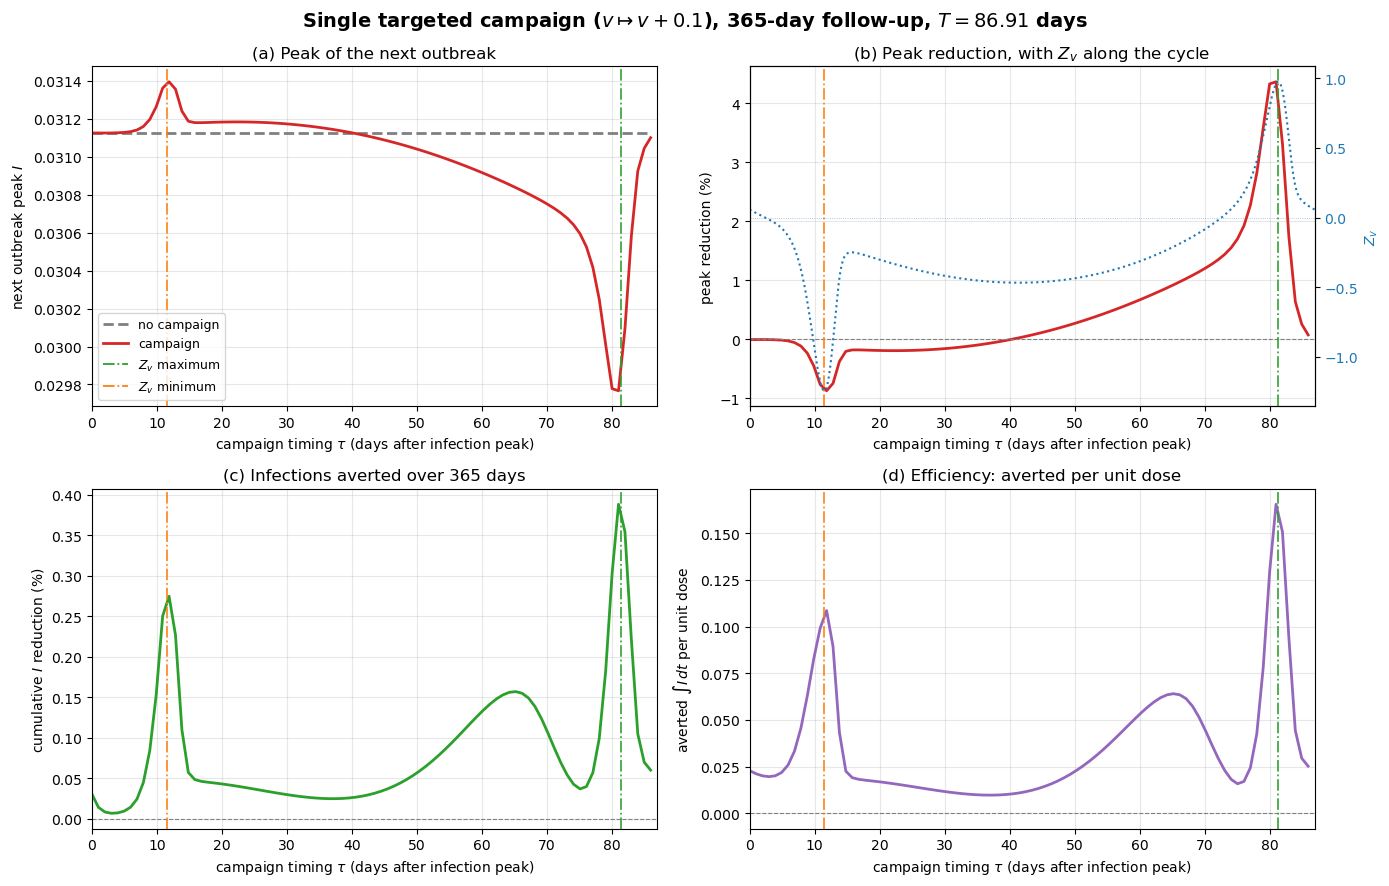


wrote campaign_timing_sweep.png
dash-dot lines mark the Z_v extrema (max at 81.32 d, min at 11.49 d)


In [11]:
"""
Targeted vaccination campaign: does the timing matter?

Pure simulation, no phase reduction.  The system is settled onto its limit
cycle, a SINGLE campaign v -> min(v + DOSE, 1) is applied tau days after an
infection peak, and the result is compared against the identical trajectory
without the campaign.  tau is swept over one full period.

Reported per tau:
    next-outbreak peak I      (first I maximum after the campaign)
    cumulative I              (integral of I over HORIZON days from the campaign)
    infections averted        (baseline minus campaign, both quantities)
    averted per unit dose     (cumulative averted / dose actually delivered)

The baseline trajectory does not depend on tau, so it is computed once and
re-evaluated on each tau's window via dense output.
"""

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

_trapz = getattr(np, 'trapezoid', None) or np.trapz   # numpy 1.x / 2.x


# =============================================================================
# SETTINGS
# =============================================================================

params = {
    'alpha': 0.01,
    'beta': 0.5,
    'gamma': 1/7,
    'eta': 1/7,
    'theta': 0.01,
    'kappa': 300,
    'rho': 0.01,
}

y0_init = [0.49, 0.01, 0.01]

DOSE = 0.10            # additive bump to v, capped at 1
HORIZON = 365.0        # days of follow-up from the campaign
N_TAU = 88             # tau grid points over [0, T)  (~1 day spacing)
DT_OUT = 0.01          # output resolution for peaks and integrals
RTOL = ATOL = 1e-10

OUTFILE = 'campaign_timing_sweep.png'


# =============================================================================
# SYSTEM
# =============================================================================

def f(t, y, p):
    """Uncoupled smooth SIRv system. y = [S, I, v]"""
    S, I, v = y
    dS = p['alpha']*(1 - S - I) - p['beta']*S*I - p['eta']*v*S
    dI = -p['gamma']*I + p['beta']*S*I
    dv = -v + 1/(1 + np.exp(-p['kappa']*(p['beta']*I - p['rho']
                                         - p['theta']*(1 - 2*v))))
    return [dS, dI, dv]


def rhs(t, y):
    return f(t, y, params)


def ev_Imax(t, y):
    """dI/dt = I*(beta*S - gamma); zero with direction -1 is an I maximum."""
    return y[1]*(params['beta']*y[0] - params['gamma'])


ev_Imax.direction = -1.0


# =============================================================================
# STEP 1: SETTLE ONTO THE LIMIT CYCLE, START AT AN INFECTION PEAK
# =============================================================================

settle = solve_ivp(rhs, (0, 5000), y0_init, method='LSODA',
                   rtol=RTOL, atol=ATOL)

pk = solve_ivp(rhs, (0, 1000), settle.y[:, -1], method='LSODA',
               rtol=RTOL, atol=ATOL, events=ev_Imax)

peak_times = pk.t_events[0]
T = float(np.mean(np.diff(peak_times[-5:])))
y0 = pk.y_events[0][-3].copy()          # a peak with room to run afterwards

print(f"Period T = {T:.6f} days")
print(f"Start state at I peak: S={y0[0]:.6f}, I={y0[1]:.6f}, v={y0[2]:.6f}")
print(f"Dose = {DOSE}, horizon = {HORIZON:.0f} days "
      f"({HORIZON/T:.2f} cycles)\n")


# =============================================================================
# STEP 1b: iPRC LANDMARKS FOR THE FIGURE
# =============================================================================

n_points = 20000
n_periods = 20

t_cycle = np.linspace(0, T, n_points)

sol_cycle = solve_ivp(
    lambda t, y: f(t, y, params),
    [0, T],
    y0,
    method='LSODA',
    t_eval=t_cycle,
    rtol=RTOL,
    atol=ATOL
)


class Gamma:
    t = sol_cycle.t
    S = sol_cycle.y[0, :]
    I = sol_cycle.y[1, :]
    v = sol_cycle.y[2, :]
    T = T
    y = sol_cycle.y


S_sym, I_sym, v_sym = sp.symbols('S I v')
alpha_sym, beta_sym, gamma_sym, eta_sym = sp.symbols('alpha beta gamma eta')
theta_sym, kappa_sym, rho_sym = sp.symbols('theta kappa rho')

F1 = alpha_sym*(1 - S_sym - I_sym) - beta_sym*S_sym*I_sym - eta_sym*v_sym*S_sym
F2 = -gamma_sym*I_sym + beta_sym*S_sym*I_sym
F3 = -v_sym + 1/(1 + sp.exp(-kappa_sym*(beta_sym*I_sym - rho_sym
                                        - theta_sym*(1 - 2*v_sym))))

F = sp.Matrix([F1, F2, F3])
state = sp.Matrix([S_sym, I_sym, v_sym])

DF_symbolic = F.jacobian(state)

param_symbols = (alpha_sym, beta_sym, gamma_sym, eta_sym,
                 theta_sym, kappa_sym, rho_sym)
all_symbols = (S_sym, I_sym, v_sym) + param_symbols

DF_func = sp.lambdify(all_symbols, DF_symbolic, modules='numpy')


def compute_DF(S, I, v, params):
    return np.array(DF_func(
        S, I, v,
        params['alpha'], params['beta'], params['gamma'], params['eta'],
        params['theta'], params['kappa'], params['rho']
    ))


A = np.zeros((n_points, 3, 3))
for i in range(n_points):
    A[i] = compute_DF(Gamma.S[i], Gamma.I[i], Gamma.v[i], params)

Gamma_dot = np.zeros((3, n_points))
for i in range(n_points):
    Gamma_dot[:, i] = f(Gamma.t[i], Gamma.y[:, i], params)

Gamma.S_dot = Gamma_dot[0, :]
Gamma.I_dot = Gamma_dot[1, :]
Gamma.v_dot = Gamma_dot[2, :]
Gamma.y_dot = Gamma_dot

A_interp_base = interp1d(Gamma.t, A, axis=0, kind='linear',
                         fill_value='extrapolate')


def A_interp_periodic(t):
    t_mod = np.mod(t, Gamma.T)
    return A_interp_base(t_mod)


def adjoint_equation_reversed_periodic(s, Z, T):
    A_t = A_interp_periodic(T - (s % T))
    return A_t.T @ Z


total_time = n_periods * Gamma.T

Z_initial = np.array([1.0, 1.0, 1.0])

n_points_total = n_points * n_periods
s_eval = np.linspace(0, total_time, n_points_total)

sol_adjoint = solve_ivp(
    lambda s, Z: adjoint_equation_reversed_periodic(s, Z, Gamma.T),
    [0, total_time],
    Z_initial,
    method='RK45',
    t_eval=s_eval,
    rtol=1e-10,
    atol=1e-12
)

last_period_start_idx = (n_periods - 1) * n_points
Z_raw = sol_adjoint.y[:, last_period_start_idx:]

Z_raw = Z_raw[:, ::-1]

if Z_raw.shape[1] != n_points:
    t_raw = np.linspace(0, Gamma.T, Z_raw.shape[1])
    Z_raw_interp = np.zeros((3, n_points))
    for i in range(3):
        Z_raw_interp[i, :] = np.interp(Gamma.t, t_raw, Z_raw[i, :])
    Z_raw = Z_raw_interp

omega = 2 * np.pi / Gamma.T

Z_dot_Gamma_dot = np.sum(Z_raw * Gamma_dot, axis=0)

Z_normalized = Z_raw * omega / Z_dot_Gamma_dot

t_cyc = Gamma.t
Zv = Z_normalized[2, :]

tau_Zv_max = float(Gamma.t[np.argmax(Zv)])
tau_Zv_min = float(Gamma.t[np.argmin(Zv)])


# =============================================================================
# STEP 2: BASELINE (NO CAMPAIGN) -- COMPUTED ONCE
# =============================================================================

T_END = T + HORIZON + 10.0

base = solve_ivp(rhs, (0, T_END), y0, method='LSODA',
                 rtol=RTOL, atol=ATOL, dense_output=True, events=ev_Imax)

base_peak_t = base.t_events[0]
base_peak_I = base.y_events[0][:, 1]


def first_peak_after(t0, times, values):
    """First (time, I) peak strictly after t0."""
    k = np.searchsorted(times, t0, side='right')
    if k >= len(times):
        return np.nan, np.nan
    return float(times[k]), float(values[k])


# =============================================================================
# STEP 3: SWEEP tau
# =============================================================================

tau_list = np.linspace(0.0, T, N_TAU + 1)[:-1]
rows = []

for tau in tau_list:
    # --- integrate up to the campaign, then apply it --------------------
    if tau <= 0.0:
        y_pre = y0.copy()
    else:
        seg = solve_ivp(rhs, (0, tau), y0, method='LSODA',
                        rtol=RTOL, atol=ATOL)
        y_pre = seg.y[:, -1].copy()

    S_at, I_at, v_at = y_pre
    y_post = y_pre.copy()
    y_post[2] = min(v_at + DOSE, 1.0)
    delivered = y_post[2] - v_at

    # --- follow-up with the campaign ------------------------------------
    kick = solve_ivp(rhs, (tau, tau + HORIZON), y_post, method='LSODA',
                     rtol=RTOL, atol=ATOL, dense_output=True, events=ev_Imax)

    # --- next outbreak peak, campaign vs baseline -----------------------
    pk_t_k, pk_I_k = first_peak_after(tau, kick.t_events[0],
                                      kick.y_events[0][:, 1])
    pk_t_b, pk_I_b = first_peak_after(tau, base_peak_t, base_peak_I)

    # --- cumulative I over the same window ------------------------------
    grid = np.linspace(tau, tau + HORIZON, int(HORIZON/DT_OUT) + 1)
    cum_k = float(_trapz(kick.sol(grid)[1], grid))
    cum_b = float(_trapz(base.sol(grid)[1], grid))

    averted = cum_b - cum_k

    rows.append(dict(
        tau=tau, phi=2*np.pi*tau/T, S_at=S_at, I_at=I_at, v_at=v_at,
        delivered=delivered,
        peak_k=pk_I_k, peak_b=pk_I_b,
        peak_red=100*(pk_I_b - pk_I_k)/pk_I_b,
        peak_shift=pk_t_k - pk_t_b,
        cum_k=cum_k, cum_b=cum_b, averted=averted,
        cum_red=100*averted/cum_b,
        per_dose=averted/delivered if delivered > 0 else np.nan,
    ))

R = {k: np.array([r[k] for r in rows]) for k in rows[0]}


# =============================================================================
# STEP 4: REPORT
# =============================================================================

print(f"{'tau':>7} {'phi/pi':>7} {'S':>7} {'v':>7} {'dose':>6} "
      f"{'peak_base':>10} {'peak_camp':>10} {'peak_red%':>10} "
      f"{'cum_red%':>9} {'avert/dose':>11}")
print('-'*100)
for r in rows:
    print(f"{r['tau']:7.2f} {r['phi']/np.pi:7.3f} {r['S_at']:7.4f} "
          f"{r['v_at']:7.4f} {r['delivered']:6.3f} "
          f"{r['peak_b']:10.6f} {r['peak_k']:10.6f} {r['peak_red']:+10.3f} "
          f"{r['cum_red']:+9.3f} {r['per_dose']:+11.4f}")

i_pk = int(np.nanargmax(R['peak_red']))
i_cu = int(np.nanargmax(R['cum_red']))
i_pd = int(np.nanargmax(R['per_dose']))
i_S = int(np.argmax(R['S_at']))

print("\n" + "="*62)
print(f"largest next-peak reduction : tau = {R['tau'][i_pk]:6.2f} d "
      f"({R['phi'][i_pk]/np.pi:.3f} pi)   {R['peak_red'][i_pk]:+.3f}%")
print(f"largest cumulative reduction: tau = {R['tau'][i_cu]:6.2f} d "
      f"({R['phi'][i_cu]/np.pi:.3f} pi)   {R['cum_red'][i_cu]:+.3f}%")
print(f"best averted per dose       : tau = {R['tau'][i_pd]:6.2f} d "
      f"({R['phi'][i_pd]/np.pi:.3f} pi)   {R['per_dose'][i_pd]:+.4f}")
print(f"S maximum                   : tau = {R['tau'][i_S]:6.2f} d "
      f"({R['phi'][i_S]/np.pi:.3f} pi)   S = {R['S_at'][i_S]:.4f}")
print(f"Z_v maximum                 : tau = {tau_Zv_max:6.2f} d "
      f"({2*tau_Zv_max/T:.3f} pi)")
print(f"Z_v minimum                 : tau = {tau_Zv_min:6.2f} d "
      f"({2*tau_Zv_min/T:.3f} pi)")
print(f"\nworst-to-best spread, cumulative reduction: "
      f"{np.nanmin(R['cum_red']):+.3f}% to {np.nanmax(R['cum_red']):+.3f}%")
print(f"dose was capped below {DOSE} at "
      f"{int(np.sum(R['delivered'] < DOSE - 1e-12))} of {len(rows)} phases")


# =============================================================================
# STEP 5: PLOT
# =============================================================================

tau = R['tau']
C_MAX, C_MIN = '#2ca02c', '#ff7f0e'      # Z_v max / Z_v min marker colours

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(f'Single targeted campaign ($v \\mapsto v + {DOSE}$), '
             f'{HORIZON:.0f}-day follow-up, $T = {T:.2f}$ days',
             fontsize=14, fontweight='bold')

a = ax[0, 0]
a.plot(tau, R['peak_b'], color='0.5', lw=2, ls='--', label='no campaign')
a.plot(tau, R['peak_k'], color='#d62728', lw=2, label='campaign')
a.set_ylabel('next outbreak peak $I$')
a.set_title('(a) Peak of the next outbreak')
a.legend(handles=[
    plt.Line2D([], [], color='0.5', lw=2, ls='--', label='no campaign'),
    plt.Line2D([], [], color='#d62728', lw=2, label='campaign'),
    plt.Line2D([], [], color=C_MAX, lw=1.3, ls='-.', label='$Z_v$ maximum'),
    plt.Line2D([], [], color=C_MIN, lw=1.3, ls='-.', label='$Z_v$ minimum'),
], fontsize=9, loc='lower left')

a = ax[0, 1]
a.plot(tau, R['peak_red'], color='#d62728', lw=2)
a.axhline(0, color='0.5', lw=0.8, ls='--')
a.set_ylabel('peak reduction (%)')
a.set_title('(b) Peak reduction, with $Z_v$ along the cycle')
at = a.twinx()
at.plot(t_cyc, Zv, color='#1f77b4', lw=1.5, ls=':')
at.axhline(0, color='#1f77b4', lw=0.6, ls=':', alpha=0.5)
at.set_ylabel('$Z_v$', color='#1f77b4')
at.tick_params(axis='y', labelcolor='#1f77b4')

a = ax[1, 0]
a.plot(tau, R['cum_red'], color='#2ca02c', lw=2)
a.axhline(0, color='0.5', lw=0.8, ls='--')
a.set_ylabel('cumulative $I$ reduction (%)')
a.set_title(f'(c) Infections averted over {HORIZON:.0f} days')

a = ax[1, 1]
a.plot(tau, R['per_dose'], color='#9467bd', lw=2)
a.axhline(0, color='0.5', lw=0.8, ls='--')
a.set_ylabel('averted $\\int I\\,dt$ per unit dose')
a.set_title('(d) Efficiency: averted per unit dose')

for a in ax.ravel():
    a.set_xlabel('campaign timing $\\tau$ (days after infection peak)')
    a.set_xlim(0, T)
    a.axvline(tau_Zv_max, color=C_MAX, lw=1.3, ls='-.', alpha=0.9)
    a.axvline(tau_Zv_min, color=C_MIN, lw=1.3, ls='-.', alpha=0.9)
    a.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(OUTFILE, dpi=150, bbox_inches='tight')
plt.show()

print(f"\nwrote {OUTFILE}")
print(f"dash-dot lines mark the Z_v extrema "
      f"(max at {tau_Zv_max:.2f} d, min at {tau_Zv_min:.2f} d)")

## one time campaign, kappa = 400

Period T = 91.706818 days
Start state at I peak: S=0.285714, I=0.035729, v=0.977716
Dose = 0.1, horizon = 365 days (3.98 cycles)

    tau  phi/pi       S       v   dose  peak_base  peak_camp  peak_red%  cum_red%  avert/dose
----------------------------------------------------------------------------------------------------
   0.00   0.000  0.2857  0.9777  0.022   0.035729   0.035729     +0.000    +0.002     +0.0028
   1.04   0.023  0.2489  0.9916  0.008   0.035729   0.035730     -0.001    +0.001     +0.0040
   2.08   0.045  0.2178  0.9964  0.004   0.035729   0.035730     -0.001    +0.001     +0.0065
   3.13   0.068  0.1918  0.9979  0.002   0.035729   0.035729     -0.000    +0.000     +0.0097
   4.17   0.091  0.1701  0.9982  0.002   0.035729   0.035729     -0.000    +0.001     +0.0133
   5.21   0.114  0.1521  0.9977  0.002   0.035729   0.035730     -0.001    +0.001     +0.0173
   6.25   0.136  0.1372  0.9968  0.003   0.035729   0.035730     -0.001    +0.002     +0.0222
   7.29   0.159  

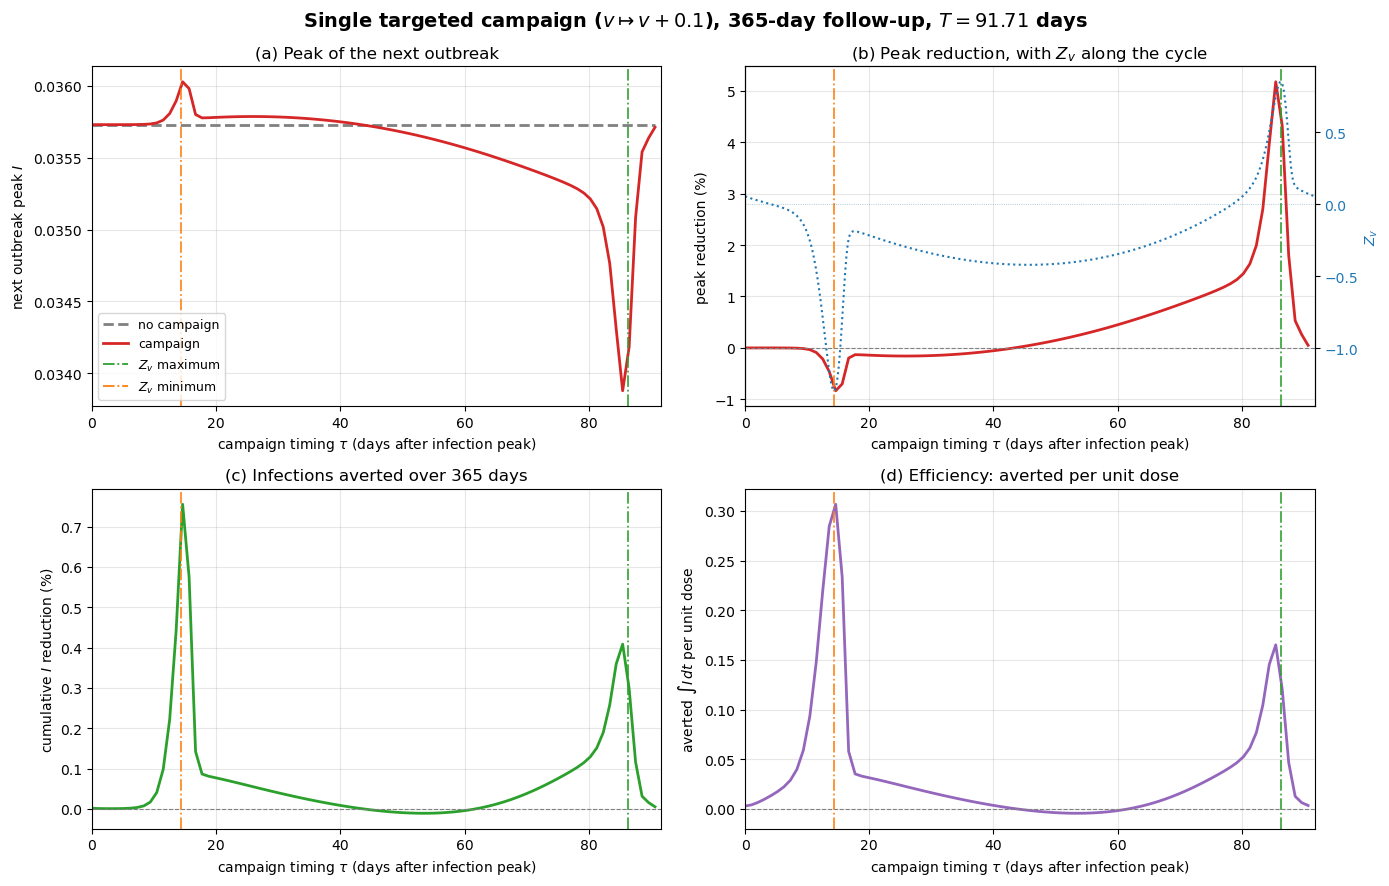


wrote campaign_timing_sweep.png
dash-dot lines mark the Z_v extrema (max at 86.25 d, min at 14.33 d)


In [13]:
"""
Targeted vaccination campaign: does the timing matter?

Pure simulation, no phase reduction.  The system is settled onto its limit
cycle, a SINGLE campaign v -> min(v + DOSE, 1) is applied tau days after an
infection peak, and the result is compared against the identical trajectory
without the campaign.  tau is swept over one full period.

Reported per tau:
    next-outbreak peak I      (first I maximum after the campaign)
    cumulative I              (integral of I over HORIZON days from the campaign)
    infections averted        (baseline minus campaign, both quantities)
    averted per unit dose     (cumulative averted / dose actually delivered)

The baseline trajectory does not depend on tau, so it is computed once and
re-evaluated on each tau's window via dense output.
"""

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

_trapz = getattr(np, 'trapezoid', None) or np.trapz   # numpy 1.x / 2.x


# =============================================================================
# SETTINGS
# =============================================================================

params = {
    'alpha': 0.01,
    'beta': 0.5,
    'gamma': 1/7,
    'eta': 1/7,
    'theta': 0.01,
    'kappa': 400,
    'rho': 0.01,
}

y0_init = [0.49, 0.01, 0.01]

DOSE = 0.10            # additive bump to v, capped at 1
HORIZON = 365.0        # days of follow-up from the campaign
N_TAU = 88             # tau grid points over [0, T)  (~1 day spacing)
DT_OUT = 0.01          # output resolution for peaks and integrals
RTOL = ATOL = 1e-10

OUTFILE = 'campaign_timing_sweep.png'


# =============================================================================
# SYSTEM
# =============================================================================

def f(t, y, p):
    """Uncoupled smooth SIRv system. y = [S, I, v]"""
    S, I, v = y
    dS = p['alpha']*(1 - S - I) - p['beta']*S*I - p['eta']*v*S
    dI = -p['gamma']*I + p['beta']*S*I
    dv = -v + 1/(1 + np.exp(-p['kappa']*(p['beta']*I - p['rho']
                                         - p['theta']*(1 - 2*v))))
    return [dS, dI, dv]


def rhs(t, y):
    return f(t, y, params)


def ev_Imax(t, y):
    """dI/dt = I*(beta*S - gamma); zero with direction -1 is an I maximum."""
    return y[1]*(params['beta']*y[0] - params['gamma'])


ev_Imax.direction = -1.0


# =============================================================================
# STEP 1: SETTLE ONTO THE LIMIT CYCLE, START AT AN INFECTION PEAK
# =============================================================================

settle = solve_ivp(rhs, (0, 5000), y0_init, method='LSODA',
                   rtol=RTOL, atol=ATOL)

pk = solve_ivp(rhs, (0, 1000), settle.y[:, -1], method='LSODA',
               rtol=RTOL, atol=ATOL, events=ev_Imax)

peak_times = pk.t_events[0]
T = float(np.mean(np.diff(peak_times[-5:])))
y0 = pk.y_events[0][-3].copy()          # a peak with room to run afterwards

print(f"Period T = {T:.6f} days")
print(f"Start state at I peak: S={y0[0]:.6f}, I={y0[1]:.6f}, v={y0[2]:.6f}")
print(f"Dose = {DOSE}, horizon = {HORIZON:.0f} days "
      f"({HORIZON/T:.2f} cycles)\n")


# =============================================================================
# STEP 1b: iPRC LANDMARKS FOR THE FIGURE
# =============================================================================

n_points = 20000
n_periods = 20

t_cycle = np.linspace(0, T, n_points)

sol_cycle = solve_ivp(
    lambda t, y: f(t, y, params),
    [0, T],
    y0,
    method='LSODA',
    t_eval=t_cycle,
    rtol=RTOL,
    atol=ATOL
)


class Gamma:
    t = sol_cycle.t
    S = sol_cycle.y[0, :]
    I = sol_cycle.y[1, :]
    v = sol_cycle.y[2, :]
    T = T
    y = sol_cycle.y


S_sym, I_sym, v_sym = sp.symbols('S I v')
alpha_sym, beta_sym, gamma_sym, eta_sym = sp.symbols('alpha beta gamma eta')
theta_sym, kappa_sym, rho_sym = sp.symbols('theta kappa rho')

F1 = alpha_sym*(1 - S_sym - I_sym) - beta_sym*S_sym*I_sym - eta_sym*v_sym*S_sym
F2 = -gamma_sym*I_sym + beta_sym*S_sym*I_sym
F3 = -v_sym + 1/(1 + sp.exp(-kappa_sym*(beta_sym*I_sym - rho_sym
                                        - theta_sym*(1 - 2*v_sym))))

F = sp.Matrix([F1, F2, F3])
state = sp.Matrix([S_sym, I_sym, v_sym])

DF_symbolic = F.jacobian(state)

param_symbols = (alpha_sym, beta_sym, gamma_sym, eta_sym,
                 theta_sym, kappa_sym, rho_sym)
all_symbols = (S_sym, I_sym, v_sym) + param_symbols

DF_func = sp.lambdify(all_symbols, DF_symbolic, modules='numpy')


def compute_DF(S, I, v, params):
    return np.array(DF_func(
        S, I, v,
        params['alpha'], params['beta'], params['gamma'], params['eta'],
        params['theta'], params['kappa'], params['rho']
    ))


A = np.zeros((n_points, 3, 3))
for i in range(n_points):
    A[i] = compute_DF(Gamma.S[i], Gamma.I[i], Gamma.v[i], params)

Gamma_dot = np.zeros((3, n_points))
for i in range(n_points):
    Gamma_dot[:, i] = f(Gamma.t[i], Gamma.y[:, i], params)

Gamma.S_dot = Gamma_dot[0, :]
Gamma.I_dot = Gamma_dot[1, :]
Gamma.v_dot = Gamma_dot[2, :]
Gamma.y_dot = Gamma_dot

A_interp_base = interp1d(Gamma.t, A, axis=0, kind='linear',
                         fill_value='extrapolate')


def A_interp_periodic(t):
    t_mod = np.mod(t, Gamma.T)
    return A_interp_base(t_mod)


def adjoint_equation_reversed_periodic(s, Z, T):
    A_t = A_interp_periodic(T - (s % T))
    return A_t.T @ Z


total_time = n_periods * Gamma.T

Z_initial = np.array([1.0, 1.0, 1.0])

n_points_total = n_points * n_periods
s_eval = np.linspace(0, total_time, n_points_total)

sol_adjoint = solve_ivp(
    lambda s, Z: adjoint_equation_reversed_periodic(s, Z, Gamma.T),
    [0, total_time],
    Z_initial,
    method='RK45',
    t_eval=s_eval,
    rtol=1e-10,
    atol=1e-12
)

last_period_start_idx = (n_periods - 1) * n_points
Z_raw = sol_adjoint.y[:, last_period_start_idx:]

Z_raw = Z_raw[:, ::-1]

if Z_raw.shape[1] != n_points:
    t_raw = np.linspace(0, Gamma.T, Z_raw.shape[1])
    Z_raw_interp = np.zeros((3, n_points))
    for i in range(3):
        Z_raw_interp[i, :] = np.interp(Gamma.t, t_raw, Z_raw[i, :])
    Z_raw = Z_raw_interp

omega = 2 * np.pi / Gamma.T

Z_dot_Gamma_dot = np.sum(Z_raw * Gamma_dot, axis=0)

Z_normalized = Z_raw * omega / Z_dot_Gamma_dot

t_cyc = Gamma.t
Zv = Z_normalized[2, :]

tau_Zv_max = float(Gamma.t[np.argmax(Zv)])
tau_Zv_min = float(Gamma.t[np.argmin(Zv)])


# =============================================================================
# STEP 2: BASELINE (NO CAMPAIGN) -- COMPUTED ONCE
# =============================================================================

T_END = T + HORIZON + 10.0

base = solve_ivp(rhs, (0, T_END), y0, method='LSODA',
                 rtol=RTOL, atol=ATOL, dense_output=True, events=ev_Imax)

base_peak_t = base.t_events[0]
base_peak_I = base.y_events[0][:, 1]


def first_peak_after(t0, times, values):
    """First (time, I) peak strictly after t0."""
    k = np.searchsorted(times, t0, side='right')
    if k >= len(times):
        return np.nan, np.nan
    return float(times[k]), float(values[k])


# =============================================================================
# STEP 3: SWEEP tau
# =============================================================================

tau_list = np.linspace(0.0, T, N_TAU + 1)[:-1]
rows = []

for tau in tau_list:
    # --- integrate up to the campaign, then apply it --------------------
    if tau <= 0.0:
        y_pre = y0.copy()
    else:
        seg = solve_ivp(rhs, (0, tau), y0, method='LSODA',
                        rtol=RTOL, atol=ATOL)
        y_pre = seg.y[:, -1].copy()

    S_at, I_at, v_at = y_pre
    y_post = y_pre.copy()
    y_post[2] = min(v_at + DOSE, 1.0)
    delivered = y_post[2] - v_at

    # --- follow-up with the campaign ------------------------------------
    kick = solve_ivp(rhs, (tau, tau + HORIZON), y_post, method='LSODA',
                     rtol=RTOL, atol=ATOL, dense_output=True, events=ev_Imax)

    # --- next outbreak peak, campaign vs baseline -----------------------
    pk_t_k, pk_I_k = first_peak_after(tau, kick.t_events[0],
                                      kick.y_events[0][:, 1])
    pk_t_b, pk_I_b = first_peak_after(tau, base_peak_t, base_peak_I)

    # --- cumulative I over the same window ------------------------------
    grid = np.linspace(tau, tau + HORIZON, int(HORIZON/DT_OUT) + 1)
    cum_k = float(_trapz(kick.sol(grid)[1], grid))
    cum_b = float(_trapz(base.sol(grid)[1], grid))

    averted = cum_b - cum_k

    rows.append(dict(
        tau=tau, phi=2*np.pi*tau/T, S_at=S_at, I_at=I_at, v_at=v_at,
        delivered=delivered,
        peak_k=pk_I_k, peak_b=pk_I_b,
        peak_red=100*(pk_I_b - pk_I_k)/pk_I_b,
        peak_shift=pk_t_k - pk_t_b,
        cum_k=cum_k, cum_b=cum_b, averted=averted,
        cum_red=100*averted/cum_b,
        per_dose=averted/delivered if delivered > 0 else np.nan,
    ))

R = {k: np.array([r[k] for r in rows]) for k in rows[0]}


# =============================================================================
# STEP 4: REPORT
# =============================================================================

print(f"{'tau':>7} {'phi/pi':>7} {'S':>7} {'v':>7} {'dose':>6} "
      f"{'peak_base':>10} {'peak_camp':>10} {'peak_red%':>10} "
      f"{'cum_red%':>9} {'avert/dose':>11}")
print('-'*100)
for r in rows:
    print(f"{r['tau']:7.2f} {r['phi']/np.pi:7.3f} {r['S_at']:7.4f} "
          f"{r['v_at']:7.4f} {r['delivered']:6.3f} "
          f"{r['peak_b']:10.6f} {r['peak_k']:10.6f} {r['peak_red']:+10.3f} "
          f"{r['cum_red']:+9.3f} {r['per_dose']:+11.4f}")

i_pk = int(np.nanargmax(R['peak_red']))
i_cu = int(np.nanargmax(R['cum_red']))
i_pd = int(np.nanargmax(R['per_dose']))
i_S = int(np.argmax(R['S_at']))

print("\n" + "="*62)
print(f"largest next-peak reduction : tau = {R['tau'][i_pk]:6.2f} d "
      f"({R['phi'][i_pk]/np.pi:.3f} pi)   {R['peak_red'][i_pk]:+.3f}%")
print(f"largest cumulative reduction: tau = {R['tau'][i_cu]:6.2f} d "
      f"({R['phi'][i_cu]/np.pi:.3f} pi)   {R['cum_red'][i_cu]:+.3f}%")
print(f"best averted per dose       : tau = {R['tau'][i_pd]:6.2f} d "
      f"({R['phi'][i_pd]/np.pi:.3f} pi)   {R['per_dose'][i_pd]:+.4f}")
print(f"S maximum                   : tau = {R['tau'][i_S]:6.2f} d "
      f"({R['phi'][i_S]/np.pi:.3f} pi)   S = {R['S_at'][i_S]:.4f}")
print(f"Z_v maximum                 : tau = {tau_Zv_max:6.2f} d "
      f"({2*tau_Zv_max/T:.3f} pi)")
print(f"Z_v minimum                 : tau = {tau_Zv_min:6.2f} d "
      f"({2*tau_Zv_min/T:.3f} pi)")
print(f"\nworst-to-best spread, cumulative reduction: "
      f"{np.nanmin(R['cum_red']):+.3f}% to {np.nanmax(R['cum_red']):+.3f}%")
print(f"dose was capped below {DOSE} at "
      f"{int(np.sum(R['delivered'] < DOSE - 1e-12))} of {len(rows)} phases")


# =============================================================================
# STEP 5: PLOT
# =============================================================================

tau = R['tau']
C_MAX, C_MIN = '#2ca02c', '#ff7f0e'      # Z_v max / Z_v min marker colours

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(f'Single targeted campaign ($v \\mapsto v + {DOSE}$), '
             f'{HORIZON:.0f}-day follow-up, $T = {T:.2f}$ days',
             fontsize=14, fontweight='bold')

a = ax[0, 0]
a.plot(tau, R['peak_b'], color='0.5', lw=2, ls='--', label='no campaign')
a.plot(tau, R['peak_k'], color='#d62728', lw=2, label='campaign')
a.set_ylabel('next outbreak peak $I$')
a.set_title('(a) Peak of the next outbreak')
a.legend(handles=[
    plt.Line2D([], [], color='0.5', lw=2, ls='--', label='no campaign'),
    plt.Line2D([], [], color='#d62728', lw=2, label='campaign'),
    plt.Line2D([], [], color=C_MAX, lw=1.3, ls='-.', label='$Z_v$ maximum'),
    plt.Line2D([], [], color=C_MIN, lw=1.3, ls='-.', label='$Z_v$ minimum'),
], fontsize=9, loc='lower left')

a = ax[0, 1]
a.plot(tau, R['peak_red'], color='#d62728', lw=2)
a.axhline(0, color='0.5', lw=0.8, ls='--')
a.set_ylabel('peak reduction (%)')
a.set_title('(b) Peak reduction, with $Z_v$ along the cycle')
at = a.twinx()
at.plot(t_cyc, Zv, color='#1f77b4', lw=1.5, ls=':')
at.axhline(0, color='#1f77b4', lw=0.6, ls=':', alpha=0.5)
at.set_ylabel('$Z_v$', color='#1f77b4')
at.tick_params(axis='y', labelcolor='#1f77b4')

a = ax[1, 0]
a.plot(tau, R['cum_red'], color='#2ca02c', lw=2)
a.axhline(0, color='0.5', lw=0.8, ls='--')
a.set_ylabel('cumulative $I$ reduction (%)')
a.set_title(f'(c) Infections averted over {HORIZON:.0f} days')

a = ax[1, 1]
a.plot(tau, R['per_dose'], color='#9467bd', lw=2)
a.axhline(0, color='0.5', lw=0.8, ls='--')
a.set_ylabel('averted $\\int I\\,dt$ per unit dose')
a.set_title('(d) Efficiency: averted per unit dose')

for a in ax.ravel():
    a.set_xlabel('campaign timing $\\tau$ (days after infection peak)')
    a.set_xlim(0, T)
    a.axvline(tau_Zv_max, color=C_MAX, lw=1.3, ls='-.', alpha=0.9)
    a.axvline(tau_Zv_min, color=C_MIN, lw=1.3, ls='-.', alpha=0.9)
    a.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(OUTFILE, dpi=150, bbox_inches='tight')
plt.show()

print(f"\nwrote {OUTFILE}")
print(f"dash-dot lines mark the Z_v extrema "
      f"(max at {tau_Zv_max:.2f} d, min at {tau_Zv_min:.2f} d)")